# BÀI 04 – CÔNG CỤ TRỰC QUAN DỮ LIỆU GITHUB REPOSITORIES

**Mục tiêu:** Vận dụng Matplotlib và Seaborn theo từng câu hỏi; mỗi biểu đồ có mục đích và giới hạn. Tài liệu Bài 04 giới thiệu quy trình 5 bước: (1) làm rõ câu hỏi, (2) hiểu dữ liệu/phác họa, (3) xác định thông điệp, (4) chọn họa đồ, (5) dùng màu, kích thước, tỷ lệ và nhãn để tập trung vào thông điệp.

## 1. Nội dung lý thuyết và lựa chọn biểu đồ

| Kỹ thuật trong tài liệu | Ý nghĩa / câu hỏi | Cách dùng trong dự án | Ghi chú |
|---|---|---|---|
| Line plot | Điểm dữ liệu được nối theo thứ tự; thể hiện tiến triển | Số repo theo năm tạo (đã làm ở Bài 03) | Không lặp lại trọng tâm ở notebook này |
| Area plot | Diện tích dưới/giữa đường, thường biểu diễn tổng tích lũy theo thời gian | Không cần vì không có nhiều chuỗi tích lũy | Có thể làm sai cảm giác quy mô nếu không giải thích |
| Histogram | Phân phối tần suất của một biến qua bins | Phân phối Stars | `log1p` chỉ cho hiển thị |
| Bar chart | So sánh giá trị danh mục tại một thời điểm | Top topics | Không dùng thay histogram |
| Pie chart | Tỷ lệ các thành phần | Doughnut đã dùng ở Bài 03 | Chỉ phù hợp ít nhóm |
| Box plot | Tóm tắt phân phối qua quartile/IQR và ngoại lệ | Stars theo Top 5 ngôn ngữ | Dùng log1p khi đuôi dài |
| Scatter plot | Quan hệ hai biến số | Stars–Forks, tô màu theo `has_wiki` | Tô màu không chứng minh nhân quả |
| Waffle chart | Tỷ lệ thành phần bằng các ô lặp | Không ưu tiên vì nhiều ngôn ngữ/topic | Cần chọn tỷ lệ và làm tròn ô |
| Word cloud | Tần suất từ trong văn bản | Không tạo từ description vì dữ liệu thiếu và nhiều văn bản kỹ thuật; chủ đề đã có `topics` có cấu trúc | Word cloud không biểu diễn số chính xác |

## 2. Matplotlib và Seaborn

| Tiêu chí | Matplotlib | Seaborn |
|---|---|---|
| Mục đích | Thư viện vẽ nền tảng, kiểm soát Figure/Axes/Artist | Giao diện cấp cao cho thống kê, dựa trên Matplotlib |
| Điểm mạnh | Tùy biến chi tiết, kiểm soát layout, phù hợp đồ thị chuyên biệt | API ngắn, chủ đề đẹp, tích hợp DataFrame, histogram/KDE/box/scatter/heatmap |
| Hạn chế | Code dài hơn với biểu đồ thống kê phức tạp | Một số mặc định che khuất chi tiết; cần hiểu dữ liệu và Matplotlib để tùy biến sâu |
| Cách dùng | `fig, ax = plt.subplots(); ax.hist(...); ax.set(...)` | `sns.histplot(data=..., x=...); sns.boxplot(...)` |
| Ví dụ dự án | Line chart năm tạo, histogram, chú giải và annotation | KDE, boxplot theo ngôn ngữ, countplot, scatter và heatmap |

**Nguyên tắc:** Matplotlib quản lý Figure/Axes và lưu ảnh; Seaborn dùng khi biểu đồ thống kê theo nhóm/ma trận giúp code rõ hơn. Không lặp lại toàn bộ Bài 03: notebook này nhấn vào các API/biểu đồ công cụ.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_common.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "analysis_common.py").is_file():
    raise FileNotFoundError("Không tìm thấy analysis_common.py trong thư mục dự án.")
sys.path.insert(0, str(PROJECT_ROOT))

import json
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from analysis_common import (
    load_raw_data, load_normalized_frames, prepare_analysis_frame,
    get_programming_language_frame, topic_frequency, save_figure,
    NUMERIC_METRICS, POPULARITY_METRICS, PROJECT_ROOT
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

raw = load_raw_data()
df = prepare_analysis_frame(raw)
lang_df = get_programming_language_frame(df)
top5_lang = lang_df["primary_language_clean"].value_counts().head(5).index.tolist()
topics = topic_frequency(df)
OUT = PROJECT_ROOT / "outputs" / "bai04"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Dataset: {len(df):,} rows; Top 5 ngôn ngữ: {', '.join(top5_lang)}")

Dataset: 12,000 rows; Top 5 ngôn ngữ: Python, TypeScript, JavaScript, Rust, Go


## 3. Thực hành biểu đồ

### 3.1. Histogram – phân phối Stars

**Câu hỏi:** Repository nằm ở dải Stars nào? Histogram cho tần suất từng bin. Trục là `log1p(star_count)` để nhìn rõ phần đông mẫu, không thay đổi giá trị gốc trong phân tích.

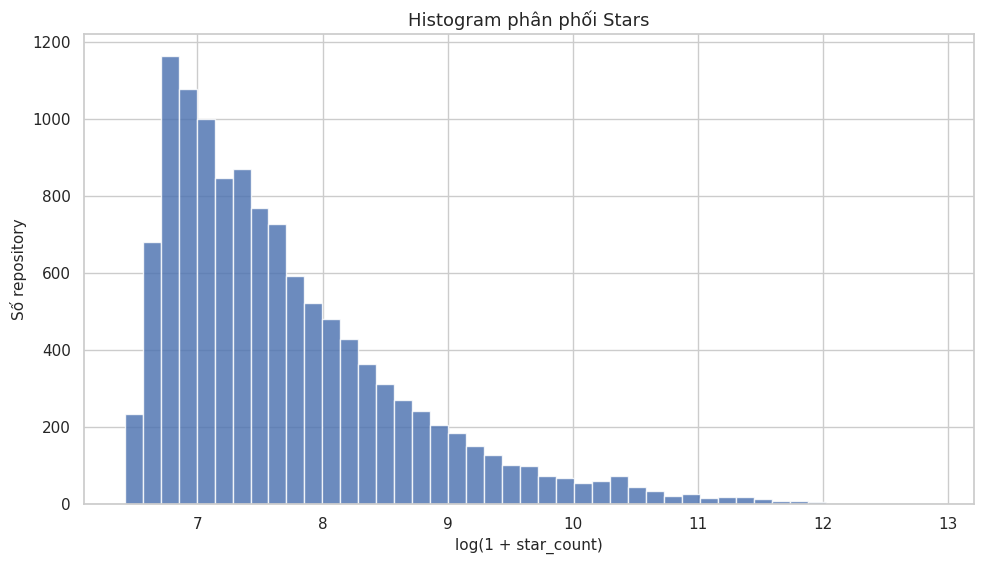

In [2]:
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.hist(np.log1p(df["star_count"]), bins=45, edgecolor="white", alpha=0.82)
ax.set(title="Histogram phân phối Stars", xlabel="log(1 + star_count)", ylabel="Số repository")
fig.tight_layout()
save_figure(fig, OUT / "bai04_histogram_stars.png")
plt.show()

### 3.2. KDE plot – đường mật độ Stars

**Câu hỏi:** Hình dạng phân phối sau khi làm trơn có một đỉnh tập trung hay nhiều vùng tập trung? KDE bổ trợ Histogram, không thay số đếm chính xác; hình dạng phụ thuộc bandwidth.

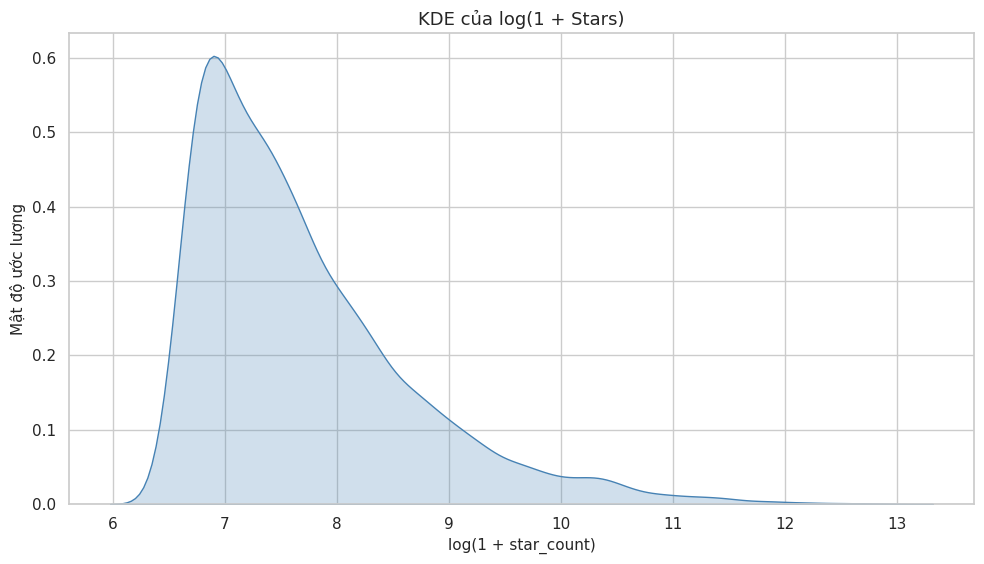

In [3]:
fig, ax = plt.subplots(figsize=(10, 5.8))
sns.kdeplot(x=np.log1p(df["star_count"]), fill=True, bw_adjust=1.0, color="steelblue", ax=ax)
ax.set(title="KDE của log(1 + Stars)", xlabel="log(1 + star_count)", ylabel="Mật độ ước lượng")
fig.tight_layout()
save_figure(fig, OUT / "bai04_kde_stars.png")
plt.show()

### 3.3. Boxplot – Stars theo Top 5 ngôn ngữ

**Câu hỏi:** Median và độ phân tán Stars có khác nhau giữa năm ngôn ngữ có nhiều repository nhất? Boxplot tóm tắt median/Q1/Q3/outlier; trục log1p để dễ quan sát.

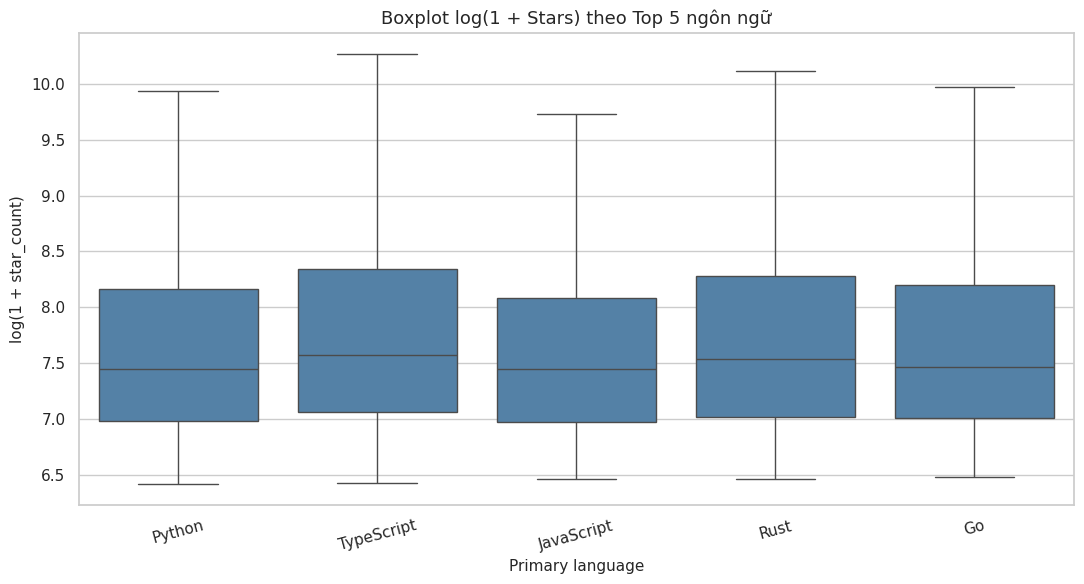

In [4]:
box_df = lang_df[lang_df["primary_language_clean"].isin(top5_lang)].copy()
box_df["log1p_stars"] = np.log1p(box_df["star_count"])
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=box_df, x="primary_language_clean", y="log1p_stars", order=top5_lang, showfliers=False, color="steelblue", ax=ax)
ax.set(title="Boxplot log(1 + Stars) theo Top 5 ngôn ngữ", xlabel="Primary language", ylabel="log(1 + star_count)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
save_figure(fig, OUT / "bai04_boxplot_stars_by_language.png")
plt.show()

### 3.4. Bar chart – Top 10 topics

**Câu hỏi:** Topic nào xuất hiện nhiều nhất? Bar chart dùng cho tần suất rời rạc theo danh mục; không dùng histogram vì topic là biến phân loại.

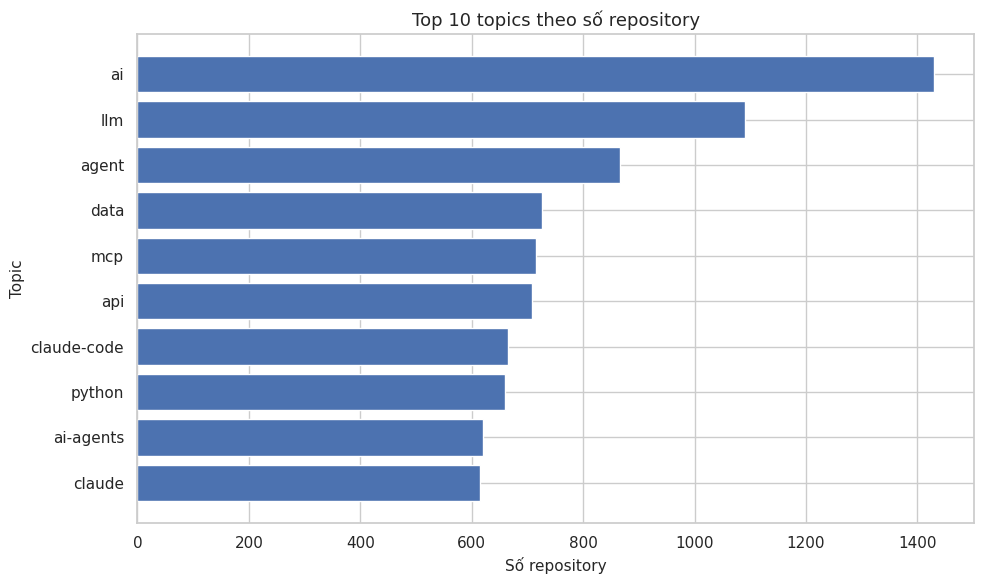

In [5]:
top10 = topics.head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10.index, top10.values)
ax.set(title="Top 10 topics theo số repository", xlabel="Số repository", ylabel="Topic")
fig.tight_layout()
save_figure(fig, OUT / "bai04_bar_top_topics.png")
plt.show()

### 3.5. Count plot – trạng thái bật Issue tracker

**Câu hỏi:** Bao nhiêu repository bật/tắt Issues? Count plot đếm số dòng theo danh mục nhị phân. Đây không phải chỉ số popularity.

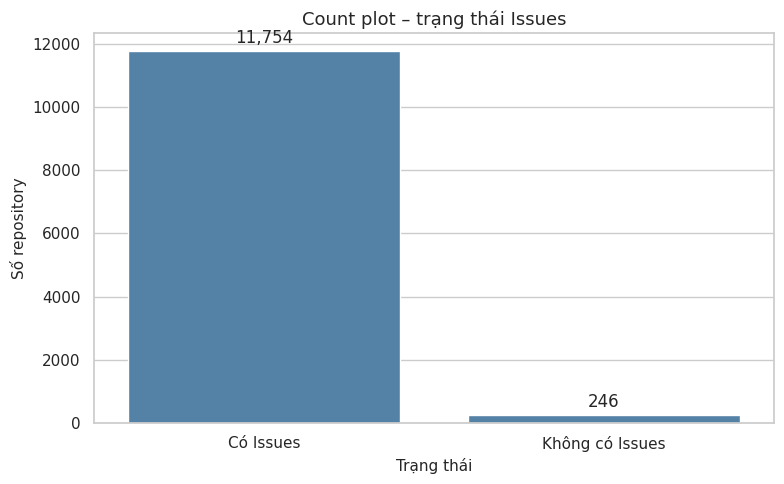

In [6]:
count_df = df.assign(has_issues_label=df["has_issues"].map({True:"Có Issues", False:"Không có Issues"}))
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=count_df, x="has_issues_label", order=["Có Issues", "Không có Issues"], color="steelblue", ax=ax)
ax.set(title="Count plot – trạng thái Issues", xlabel="Trạng thái", ylabel="Số repository")
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
fig.tight_layout()
save_figure(fig, OUT / "bai04_countplot_has_issues.png")
plt.show()

### 3.6. Scatter plot – Stars và Forks theo trạng thái Wiki

**Câu hỏi:** Quan hệ Stars–Forks có khác nhau trực quan giữa repo bật Wiki và tắt Wiki? Màu sắc mã hóa `has_wiki`; tất cả điểm biểu diễn repository. Log1p là biến đổi hiển thị; không gộp hai chỉ số.

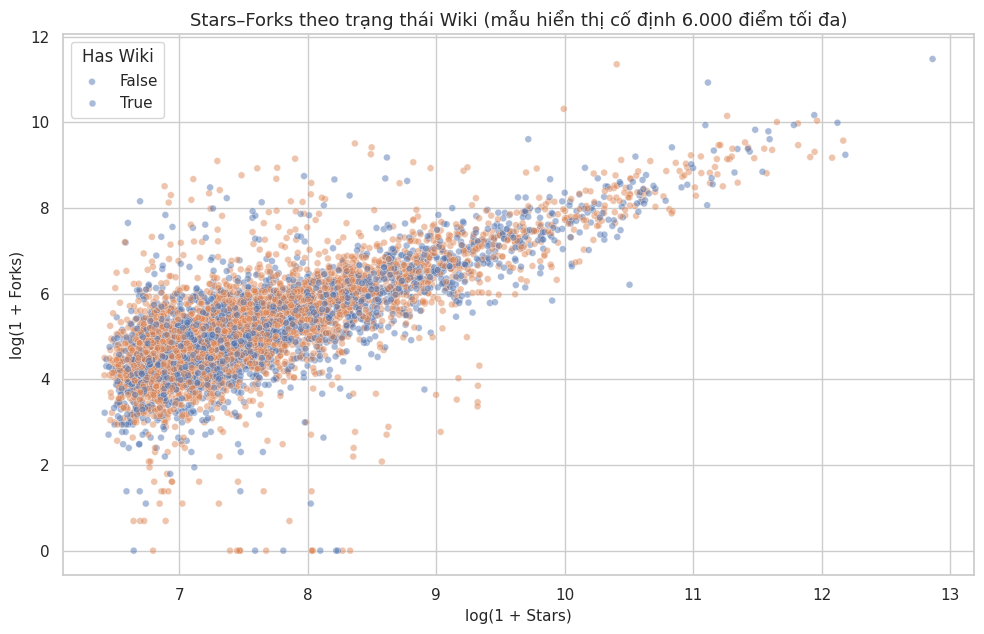

In [7]:
scatter_df = df[["star_count", "forks_count", "has_wiki"]].sample(n=min(6000, len(df)), random_state=42)
scatter_df = scatter_df.assign(log1p_stars=np.log1p(scatter_df["star_count"]), log1p_forks=np.log1p(scatter_df["forks_count"]))
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=scatter_df, x="log1p_stars", y="log1p_forks", hue="has_wiki", alpha=0.48, s=24, ax=ax)
ax.set(title="Stars–Forks theo trạng thái Wiki (mẫu hiển thị cố định 6.000 điểm tối đa)", xlabel="log(1 + Stars)", ylabel="log(1 + Forks)")
ax.legend(title="Has Wiki", labels=["False", "True"])
fig.tight_layout()
save_figure(fig, OUT / "bai04_scatter_stars_forks_by_wiki.png")
plt.show()

### 3.7. Pair plot – quan sát nhiều biến số

**Câu hỏi:** Stars, Forks và Open Issues phân tán/đồng biến thế nào khi xem theo từng cặp? Pair plot có nhiều subplot nên dùng mẫu cố định tối đa 1.500 repository và các biến đã log1p; không dùng để thay thế kiểm định trên toàn bộ dữ liệu.

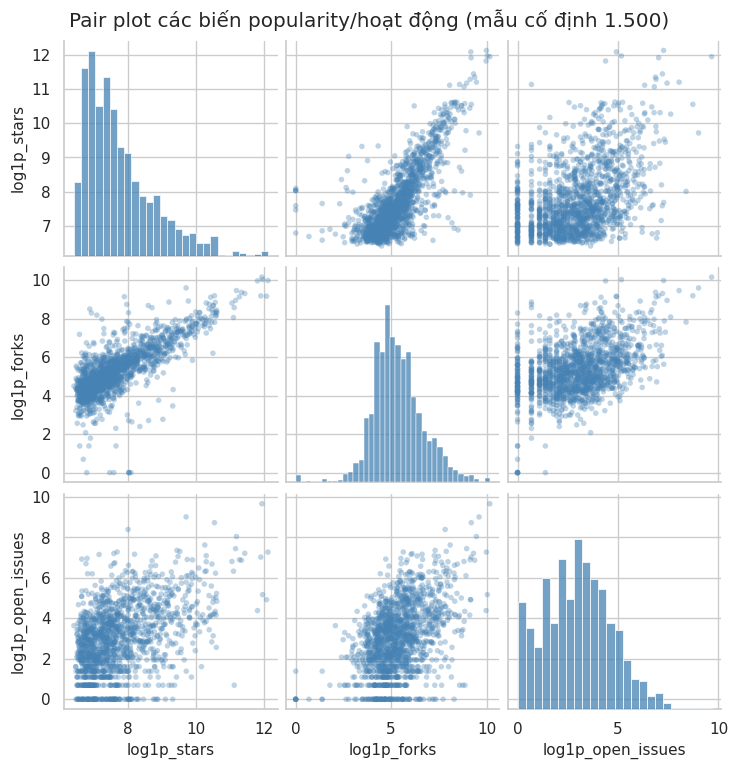

In [8]:
pair_source = df[["star_count", "forks_count", "open_issues_count"]].sample(n=min(1500, len(df)), random_state=42).copy()
pair_source = np.log1p(pair_source)
pair_source.columns = ["log1p_stars", "log1p_forks", "log1p_open_issues"]
g = sns.pairplot(pair_source, diag_kind="hist", diag_kws={"color":"steelblue"}, plot_kws={"color":"steelblue", "alpha":0.35, "s":16, "edgecolor":"none"})
g.fig.suptitle("Pair plot các biến popularity/hoạt động (mẫu cố định 1.500)", y=1.02)
save_figure(g.fig, OUT / "bai04_pairplot_numeric.png")
plt.show()

### 3.8. Heatmap – ma trận tương quan Spearman

**Câu hỏi:** Những biến số nào có liên hệ thứ hạng đáng chú ý? Spearman phù hợp để kiểm tra liên hệ đơn điệu và ít nhạy với ngoại lệ biên độ hơn Pearson. Hệ số vẫn không chứng minh nhân quả.

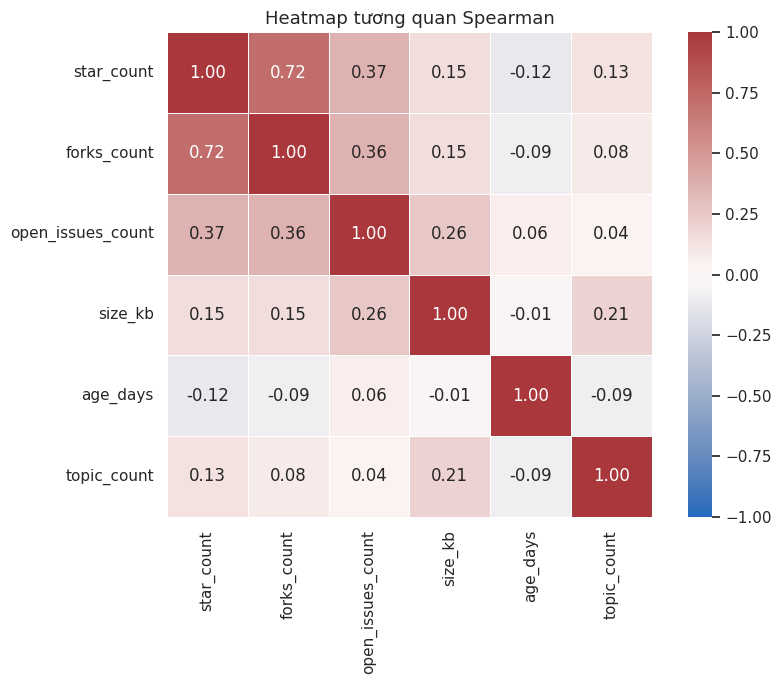

In [9]:
heat_cols = ["star_count", "forks_count", "open_issues_count", "size_kb", "age_days", "topic_count"]
corr = df[heat_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, square=True, linewidths=0.6, ax=ax)
ax.set_title("Heatmap tương quan Spearman")
fig.tight_layout()
save_figure(fig, OUT / "bai04_heatmap_spearman.png")
plt.show()

## 4. Nhận xét và giới hạn

- Histogram/KDE cho thấy phân phối Stars lệch phải; KDE chỉ là ước lượng mật độ, Histogram thể hiện tần suất.
- Boxplot cho phép so sánh trung vị và tứ phân vị của Stars giữa Top 5 ngôn ngữ; cần xem cùng kích thước từng nhóm.
- Bar chart phù hợp tần suất topic; count plot phù hợp biến Boolean `has_issues`.
- Scatterplot/Pairs/Heatmap thể hiện các góc nhìn khác nhau của biến số; khi N lớn, chồng lấp điểm và p-value nhỏ có thể làm người xem phóng đại ý nghĩa thực tiễn.
- Waffle/word cloud/area/pie không bắt buộc nếu không làm rõ câu hỏi hơn biểu đồ hiện có.

## 5. Tổng kết Matplotlib và Seaborn

Matplotlib phù hợp điều khiển chi tiết và xuất biểu đồ có chú giải/annotation. Seaborn rút gọn code cho biểu đồ thống kê. Hai thư viện bổ trợ nhau; chọn theo tác vụ, không chọn theo hiệu ứng trang trí.